# 02 - Onde o modelo erra e o que muda com o limiar?

A primeira entrega comparou três modelos e escolheu a Regressão Logística por ROC-AUC. Nesta revisão, a pergunta é outra: **o que acontece com a lista de clientes quando mudamos o limiar?**

Não vamos escolher um novo campeão nem alterar o artefato da API. O conjunto final de teste continua reservado; a análise usa uma validação interna aos 80% de treino. Os valores aqui não substituem as métricas do Model Card.

In [2]:
from pathlib import Path
import sys

# Funciona ao abrir o notebook pela raiz ou pela pasta notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/churn").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import hashlib
import json
import platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score
from threadpoolctl import threadpool_limits
from churn.config import SEED, DATA_PATH
from churn.data import load_data
from churn.pipeline import candidates

OUT = ROOT / "reports/review"
OUT.mkdir(parents=True, exist_ok=True)
X, y = load_data()


In [3]:
import sys
print(sys.executable)

c:\Users\Marco-pc\Documents\github\churn-tech-challenge-revisado\churn-tech-challenge_rewisado\.venv\Scripts\python.exe


## Separar antes de experimentar

Reproduzimos a divisão original e separamos uma validação dentro do treino. Mediana e escala serão ajustadas apenas no treino interno. O teste final não é pontuado nem inspecionado neste notebook.

A configuração do modelo já era conhecida pela primeira entrega. Portanto, esta é uma análise exploratória de revisão, não uma nova estimativa independente da seleção.

In [4]:
X_dev, X_reserved, y_dev, y_reserved = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
assert set(X_fit.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_reserved.index)
print(f"Treino interno: {len(X_fit)}; validação interna: {len(X_val)}")
print(f"Teste reservado, sem uso nesta análise: {len(X_reserved)}")
model = candidates()["logistic_regression"]
with threadpool_limits(limits=1):
    model.fit(X_fit, y_fit)
score = model.predict_proba(X_val)[:, 1]
print(f"ROC-AUC na validação interna: {roc_auc_score(y_val, score):.4f}")

Treino interno: 4225; validação interna: 1409
Teste reservado, sem uso nesta análise: 1409
ROC-AUC na validação interna: 0.8362


## Hipóteses que vamos conferir

1. Reduzir o limiar de 0,5 para 0,3 deve aumentar ou manter o recall e aumentar ou manter a quantidade de contatos.
2. A precisão também melhora quando baixamos o limiar? **Não existe essa garantia**; precisamos medir.
3. Os erros aparecem em todos os tipos de contrato? Vamos registrar contagens, sem concluir causalidade.

Maior recall não significa automaticamente melhor campanha: contatos têm custo e nem todo cancelamento pode ser evitado.

In [5]:
rows = []
for threshold in [0.3, 0.5, 0.7]:
    prediction = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
    rows.append({"threshold": threshold, "precision": precision_score(y_val, prediction, zero_division=0),
                 "recall": recall_score(y_val, prediction, zero_division=0),
                 "f1": f1_score(y_val, prediction, zero_division=0),
                 "contacts": int(prediction.sum()), "tn": int(tn), "fp": int(fp),
                 "fn": int(fn), "tp": int(tp)})
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "threshold_comparison.csv", index=False)
display(comparison.round(4))
assert comparison.loc[0, "recall"] >= comparison.loc[1, "recall"]
assert comparison.loc[0, "contacts"] >= comparison.loc[1, "contacts"]
low, default = comparison.iloc[0], comparison.iloc[1]
print(f"Ao baixar de 0,5 para 0,3: recall {default.recall:.2%} -> {low.recall:.2%}; "
      f"precisão {default.precision:.2%} -> {low.precision:.2%}; "
      f"contatos {int(default.contacts)} -> {int(low.contacts)}.")
print("A hipótese de melhora de precisão", "se confirmou nesta divisão." if low.precision > default.precision
      else "não se confirmou nesta divisão.")

,threshold,precision,recall,f1,contacts,tn,fp,fn,tp
0,0.3,0.4200,0.9118,0.5750,812,564,471,33,341
1,0.5,0.5166,0.7888,0.6243,571,759,276,79,295
2,0.7,0.6329,0.5856,0.6083,346,908,127,155,219


Ao baixar de 0,5 para 0,3: recall 78.88% -> 91.18%; precisão 51.66% -> 42.00%; contatos 571 -> 812.
A hipótese de melhora de precisão não se confirmou nesta divisão.


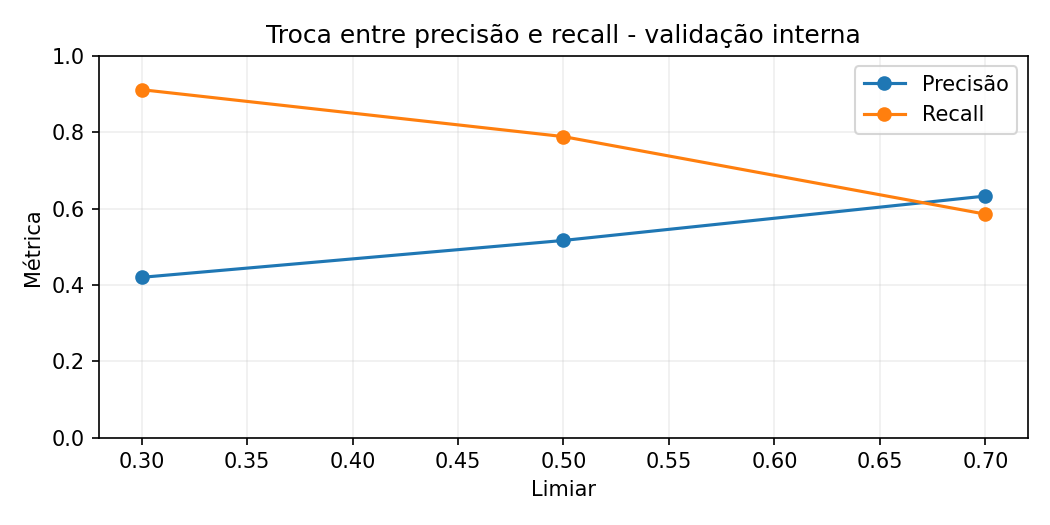

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(comparison.threshold, comparison.precision, marker="o", label="Precisão")
ax.plot(comparison.threshold, comparison.recall, marker="o", label="Recall")
ax.set(xlabel="Limiar", ylabel="Métrica", ylim=(0, 1), title="Troca entre precisão e recall - validação interna")
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "threshold_tradeoff.png", dpi=150)
from IPython.display import Image
display(Image(filename=str(OUT / "threshold_tradeoff.png")))
plt.close(fig)

## Falsos positivos e falsos negativos

**Falso positivo:** o cliente permaneceu, mas o modelo o colocou na lista de risco. **Falso negativo:** o cliente cancelou e ficou fora da lista. A classificação usa limiar 0,5 nesta tabela.

Comparamos contagens e taxas por contrato. Uma contagem maior pode refletir apenas um grupo maior; grupos com denominador zero recebem taxa ausente. Esses números não explicam por que o cliente cancelou.

In [7]:
audit = X_val[["Contract"]].copy()
audit["actual"] = y_val
audit["prediction"] = (score >= 0.5).astype(int)
audit["fp"] = (audit.actual == 0) & (audit.prediction == 1)
audit["fn"] = (audit.actual == 1) & (audit.prediction == 0)
audit["negative"] = audit.actual == 0
by_contract = audit.groupby("Contract").agg(
    n=("actual", "size"), churns=("actual", "sum"), negatives=("negative", "sum"),
    false_positives=("fp", "sum"), false_negatives=("fn", "sum"))
by_contract["false_positive_rate"] = by_contract.false_positives / by_contract.negatives.replace(0, np.nan)
by_contract["false_negative_rate"] = by_contract.false_negatives / by_contract.churns.replace(0, np.nan)
by_contract.to_csv(OUT / "errors_by_contract.csv")
display(by_contract.round(4))
metadata = {"seed": SEED, "python": platform.python_version(), "sklearn": sklearn.__version__,
            "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
            "fit_rows": len(X_fit), "validation_rows": len(X_val), "reserved_rows": len(X_reserved),
            "validation_roc_auc": roc_auc_score(y_val, score),
            "scope": "Exploração na validação interna; campeão e teste final preservados"}
(OUT / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

,n,churns,negatives,false_positives,false_negatives,false_positive_rate,false_negative_rate
Contract,,,,,,,
Month-to-month,776,324,452,257,34,0.5686,0.1049
One year,308,37,271,19,32,0.0701,0.8649
Two year,325,13,312,0,13,0.0000,1.0000


371

## O que levar para a apresentação

- Usar a tabela executada para explicar o custo de aumentar o recall.
- Distinguir métricas desta validação interna das métricas finais do projeto.
- Manter o limiar de 0,5 na API nesta revisão. Uma mudança operacional exige definir custos e capacidade de atendimento e validar a política.
- Uma única divisão não mede toda a incerteza. As taxas por contrato são descritivas, não evidência causal.

**Para a equipe discutir:** quantos clientes podem ser contatados por semana e quanto custa um contato sem necessidade? Essas respostas não estão no dataset.